# 数据分析

In [ ]:
# !pip install ultralytics

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
import shutil
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

In [2]:
def read_class_names(data_yaml_path):
    with open(data_yaml_path, 'r') as f:
        lines = f.readlines()
    names_line = next(line for line in lines if line.startswith('names:'))
    class_names = eval(names_line.split(':')[1].strip())
    return class_names 

In [3]:
data_yaml_path = 'aquarium_pretrain/data.yaml'
class_names = read_class_names(data_yaml_path)
class_names

['fish', 'jellyfish', 'penguin', 'puffin', 'shark', 'starfish', 'stingray']

In [4]:
def get_image_files(image_directory):
    """获取指定目录中所有 .jpg 文件"""
    return [f for f in os.listdir(image_directory) if f.endswith('.jpg')]

In [6]:
def select_random_images(jpg_files, num_images):
    """从图片文件列表中随机选择指定数量的图片"""
    return random.sample(jpg_files, num_images)

In [7]:
def create_subplots(num_images):
    """创建子图布局"""
    num_rows = int(num_images ** 0.5)
    num_cols = (num_images + num_rows - 1) // num_rows # 确保有足够的列数
    fig, axes = plt.subplots(num_rows, num_cols, figsize = (12, 12))

    # 如果只有一个子图，axes 不是数组，需要转换为数组
    if num_images == 1:
        axes = [axes]
    else:
        axes = axes.flatten()
    
    return fig, axes

In [8]:
def display_image_with_label(ax, image_path, label_path, label_names):
    """在子图中显示图片以及其对应的边界框和标签"""
    with Image.open(image_path) as img:
        width, height = img.size
        ax.imshow(img)
        ax.set_title(os.path.basename(image_path))
        ax.axis('off') # 关闭坐标轴

        if os.path.exists(label_path):
            with open(label_path, 'r') as label_file:
                for line in label_file:
                    label_info = line.strip().split()
                    label_id = int(label_info[0])
                    x_center, y_center, bbox_width, bbox_height = map(float, label_info[1:5])

                    # 计算边界框的左上角和右下角的坐标
                    x_min = (x_center - bbox_width / 2) * width
                    y_min = (y_center - bbox_height / 2) * height
                    x_max = (x_center + bbox_width / 2) * width
                    y_max = (y_center + bbox_height / 2) * height

                    # 绘制边界框
                    rect = plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, linewidth = 2, edgecolor = 'r', facecolor = 'none')

                    ax.add_patch(rect)
                    # 显示标签名称
                    ax.text(x_min, y_min - 5, label_names[label_id], color = 'r', fontsize = 10, backgroundcolor = 'white')

In [13]:
def display_random_images_with_labels(datasets_path, class_names, num_images = 16):
    """主函数，调用上述函数完成整体功能"""
    # 定义标签名称
    label_names = class_names
    image_directory = os.path.join(datasets_path, 'images')
    label_directory = os.path.join(datasets_path, 'labels')

    # 获取目录中所有 .jpg 文件
    jpg_files = get_image_files(image_directory)

    # 随机选择指定数量的图片
    selected_images = select_random_images(jpg_files, num_images)

    # 创建子图布局
    fig, axes = create_subplots(num_images)

    # 遍历选定的图片并显示在子图中
    for ax, selected_image in zip(axes, selected_images):
        image_path = os.path.join(image_directory, selected_image)
        label_path = os.path.join(label_directory, selected_image.replace('.jpg', '.txt'))
        display_image_with_label(ax, image_path, label_path, label_names)
    
    # 调整子图之间的间距
    plt.tight_layout()
    plt.show()

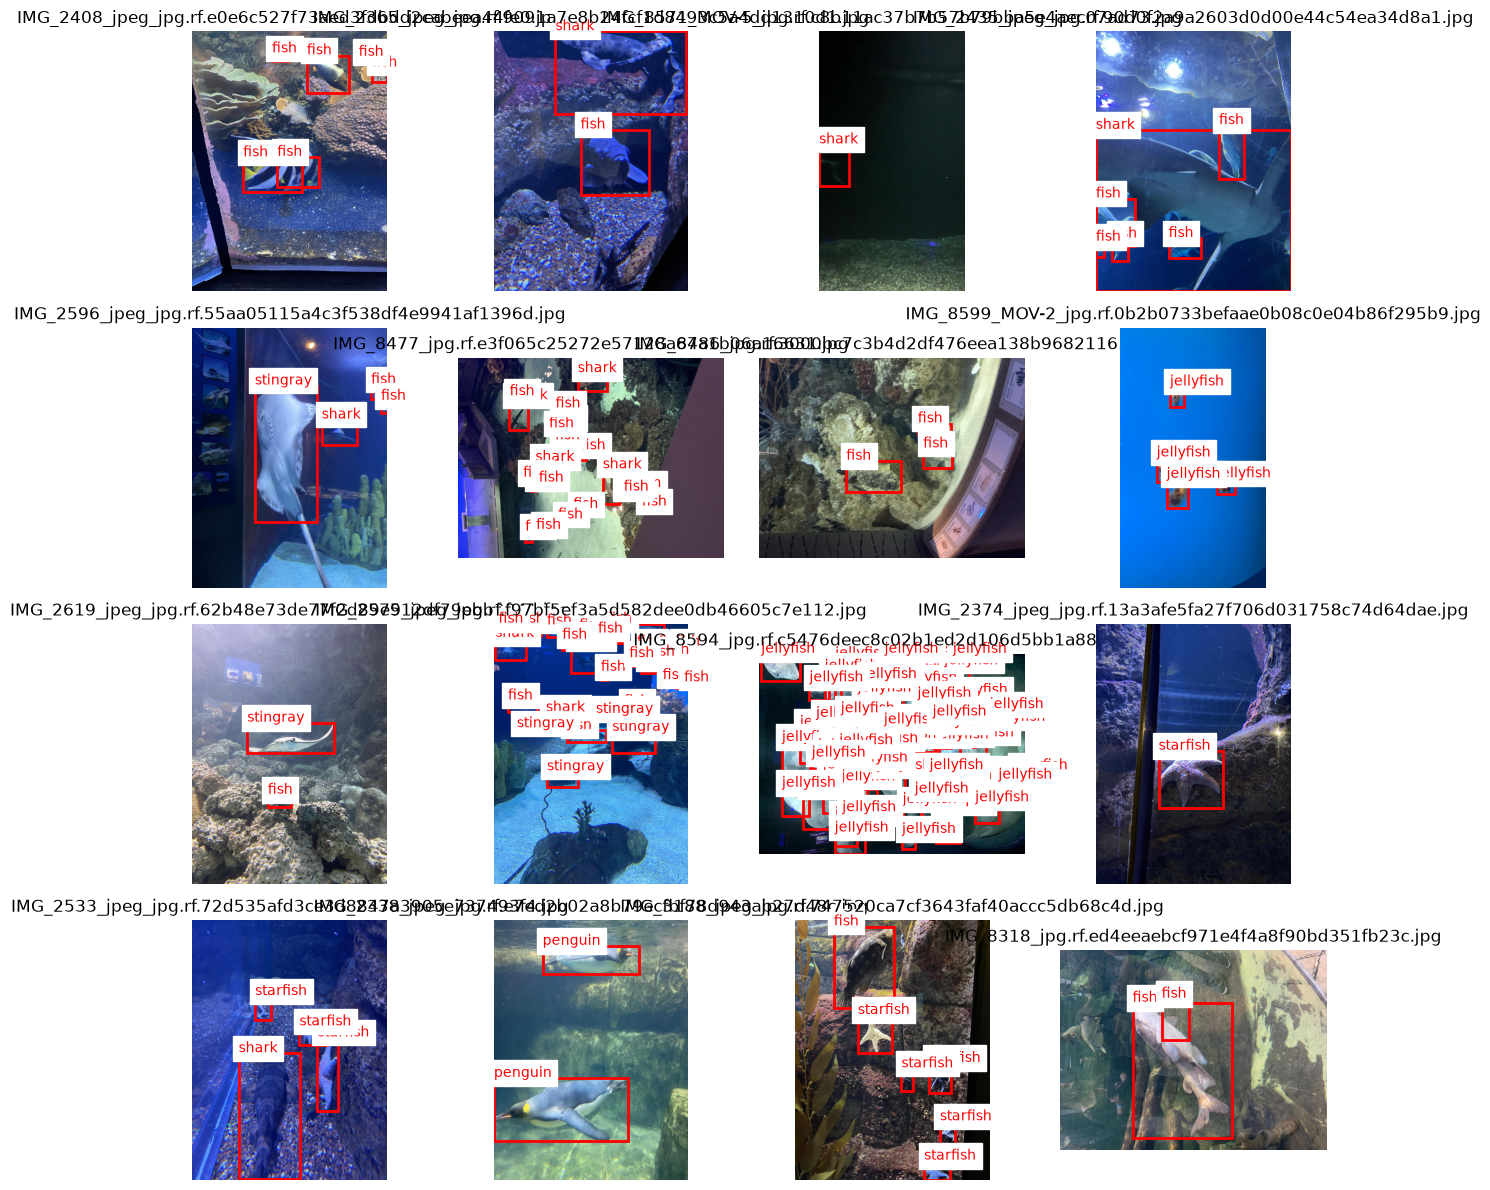

In [14]:
datasets_path = 'aquarium_pretrain/train'
display_random_images_with_labels(datasets_path, class_names, 16)